# Chapitre 5 - Cours 4 : modes de flux de données, le cas des bases de données

Les cours 1 à 3 ont comparé des formats. Mais la compatibilité est une **relation entre
deux processus** : celui qui encode et celui qui décode. Qui sont-ils ? Cela dépend de la
façon dont les données circulent. Ce cours ouvre la section *Modes of Dataflow* et traite
le premier mode, la base de données (*Dataflow Through Databases*, avec *Different values
written at different times* et *Archival storage*).

**Plan.**

1. Qui encode, qui décode ? Les modes de flux de données.
2. La base de données, un message à son futur soi.
3. Les données survivent au code : des valeurs écrites à des époques différentes.
4. Migrer sans réécrire, ou réécrire sans interrompre.
5. L'archivage : un instantané encodé avec le dernier schéma.

In [1]:
import json
import os
import sqlite3
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle, SEQ)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)
TMP = tempfile.mkdtemp(prefix="ddia_ch05_")

## 1. Qui encode, qui décode ? (section *Modes of Dataflow*)

Dès que des données quittent un processus (vers un fichier, le réseau, une base), il faut
les encoder ; un autre processus, ou le même plus tard, les décode. La compatibilité
ascendante et descendante sert l'**évolutivité** : pouvoir mettre à jour les parties d'un
système indépendamment, au lieu de tout changer d'un coup. Le livre passe en revue les
grandes façons dont les données circulent :

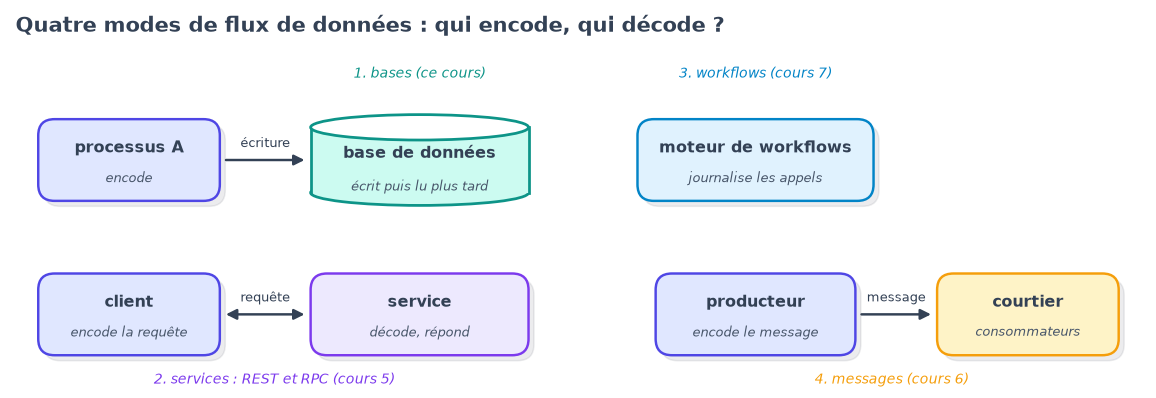

In [2]:
d = Diagram(12.5, 3.6, title="Quatre modes de flux de données : qui encode, qui décode ?")
d.box("w", 1.3, 2.5, "processus A", sub="encode", color=INDIGO, w=2.0)
d.box("db", 4.5, 2.5, "base de données", sub="écrit puis lu plus tard", color=TEAL, kind="db", w=2.4, h=1.0)
d.box("c", 1.3, 0.8, "client", sub="encode la requête", color=INDIGO, w=2.0)
d.box("s", 4.5, 0.8, "service", sub="décode, répond", color=VIOLET, w=2.4)
d.box("o", 8.2, 2.5, "moteur de workflows", sub="journalise les appels", color=SKY, w=2.6)
d.box("p", 8.2, 0.8, "producteur", sub="encode le message", color=INDIGO, w=2.2)
d.box("b", 11.2, 0.8, "courtier", sub="consommateurs", color=AMBER, w=2.0)
d.arrow("w", "db", "écriture")
d.arrow("c", "s", "requête", both=True)
d.arrow("p", "b", "message")
d.note(4.5, 3.45, "1. bases (ce cours)", color=TEAL)
d.note(2.9, 0.08, "2. services : REST et RPC (cours 5)", color=VIOLET)
d.note(8.2, 3.45, "3. workflows (cours 7)", color=SKY)
d.note(9.7, 0.08, "4. messages (cours 6)", color=AMBER)
d.show()

> **À retenir.** La compatibilité relie toujours un encodeur et un décodeur ; pour savoir
> laquelle il faut, on se demande qui écrit, qui lit, et avec quelles versions du code.

## 2. La base de données, un message à son futur soi (section *Dataflow Through Databases*)

Dans une base, le processus qui écrit encode et celui qui lit décode. S'il n'y a qu'un
processus, le lecteur est simplement une version **plus récente** du même programme :
stocker, c'est envoyer un message à son futur soi. La **compatibilité descendante** est
alors indispensable : sinon, le futur soi ne sait pas relire ce qu'il a écrit.

Mais en général plusieurs processus accèdent à la base en même temps : des applications
différentes, ou plusieurs instances d'un même service. Pendant un déploiement progressif,
certaines exécutent le nouveau code et d'autres l'ancien. Une valeur peut donc être
écrite par le nouveau code puis lue par l'ancien : la **compatibilité ascendante** est
souvent nécessaire aussi.

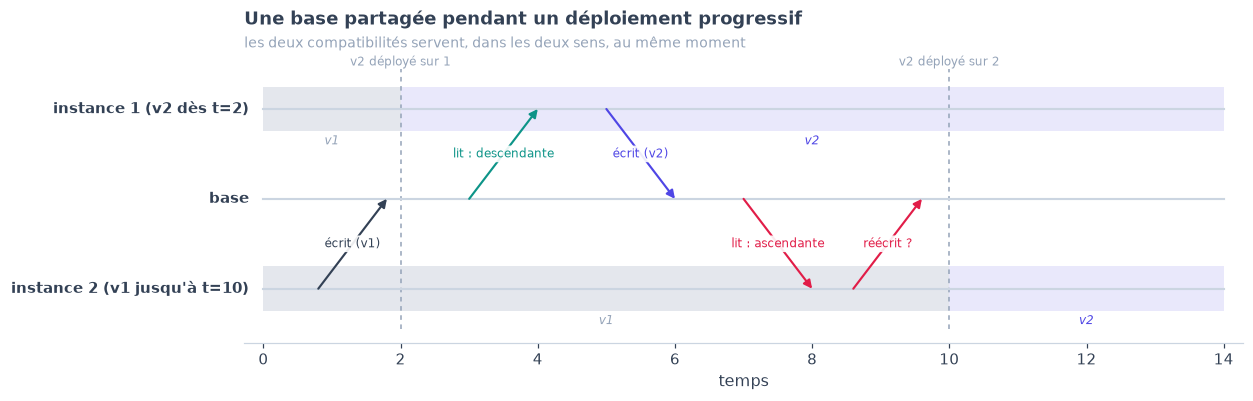

In [3]:
st = SpaceTime(["instance 1 (v2 dès t=2)", "base", "instance 2 (v1 jusqu'à t=10)"], t_max=14, width=11.5,
               title="Une base partagée pendant un déploiement progressif",
               subtitle="les deux compatibilités servent, dans les deux sens, au même moment")
st.span("instance 1 (v2 dès t=2)", 0, 2, "v1", color=GRAY)
st.span("instance 1 (v2 dès t=2)", 2, 14, "v2", color=INDIGO, alpha=0.12)
st.span("instance 2 (v1 jusqu'à t=10)", 0, 10, "v1", color=GRAY)
st.span("instance 2 (v1 jusqu'à t=10)", 10, 14, "v2", color=INDIGO, alpha=0.12)
st.msg("instance 2 (v1 jusqu'à t=10)", 0.8, "base", 1.8, "écrit (v1)", color=SLATE)
st.msg("base", 3.0, "instance 1 (v2 dès t=2)", 4.0, "lit : descendante", color=TEAL)
st.msg("instance 1 (v2 dès t=2)", 5.0, "base", 6.0, "écrit (v2)", color=INDIGO)
st.msg("base", 7.0, "instance 2 (v1 jusqu'à t=10)", 8.0, "lit : ascendante", color=ROSE)
st.msg("instance 2 (v1 jusqu'à t=10)", 8.6, "base", 9.6, "réécrit ?", color=ROSE)
st.vline(2, "v2 déployé sur 1"); st.vline(10, "v2 déployé sur 2")
st.show()

La réécriture par une instance v1 (à droite) pose à nouveau le problème des champs
inconnus (cours 1 et 2). Le format peut les préserver, mais le code applicatif doit
suivre. Avec une base relationnelle, le piège se cache souvent dans une colonne JSON :
relire le document dans un objet du modèle, le modifier et le réécrire en entier efface
les clés que l'objet ignore ; demander à la base de modifier **seulement** la clé voulue
les préserve. Démonstration avec les fonctions JSON de SQLite.

In [4]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE profils (id INTEGER PRIMARY KEY, doc TEXT)")
doc_v2 = {"nom": "Ana", "ville": "Lyon", "photo": "ana.jpg"}            # écrit par v2
con.execute("INSERT INTO profils VALUES (1, ?), (2, ?)", (json.dumps(doc_v2), json.dumps(doc_v2)))

class ProfilV1:                                     # le modèle de l'ancien code
    def __init__(self, d):
        self.nom, self.ville = d["nom"], d["ville"]
    def to_json(self):
        return json.dumps({"nom": self.nom, "ville": self.ville})

# (a) lecture-modification-écriture via le modèle v1
p = ProfilV1(json.loads(con.execute("SELECT doc FROM profils WHERE id = 1").fetchone()[0]))
p.ville = "Paris"
con.execute("UPDATE profils SET doc = ? WHERE id = 1", (p.to_json(),))
# (b) mise à jour ciblée d'une seule clé, faite par la base
con.execute("UPDATE profils SET doc = json_set(doc, '$.ville', 'Paris') WHERE id = 2")
pd.DataFrame(con.execute("SELECT id, doc FROM profils").fetchall(), columns=["id", "document après la mise à jour par v1"])

,id,document après la mise à jour par v1
0,1,"{""nom"": ""Ana"", ""ville"": ""Paris""}"
1,2,"{""nom"":""Ana"",""ville"":""Paris"",""photo"":""ana.jpg""}"


Même intention (changer la ville), deux résultats : la photo a disparu dans le premier
cas. Le livre conseille d'y penser au niveau applicatif ; ce n'est pas difficile, mais il
faut en avoir conscience.

> **À retenir.** Une base partagée exige la compatibilité descendante (le futur relit le
> passé) et, pendant les déploiements, ascendante (l'ancien code lit des valeurs
> nouvelles). Le code applicatif doit éviter d'effacer ce qu'il ne comprend pas.

## 3. Les données survivent au code (section *Different values written at different times*)

Une base permet en général de mettre à jour n'importe quelle valeur à tout moment. On y
trouve donc des valeurs écrites il y a cinq millisecondes et d'autres il y a cinq ans.
Déployer une nouvelle version du code remplace l'ancienne en quelques minutes ; mais les
données de cinq ans sont toujours là, dans leur encodage d'origine, tant que personne ne
les a réécrites. On résume cela par une formule : **les données survivent au code** (data
outlives code).

Simulons trois ans d'une base : 2 000 nouveaux enregistrements par semaine, une nouvelle
version du schéma chaque trimestre, et des mises à jour qui touchent surtout les
enregistrements récents (un enregistrement est mis à jour avec une probabilité
hebdomadaire qui décroît avec son âge). Chaque écriture réencode l'enregistrement avec la
version courante. Quelles versions trouve-t-on sur le disque ?

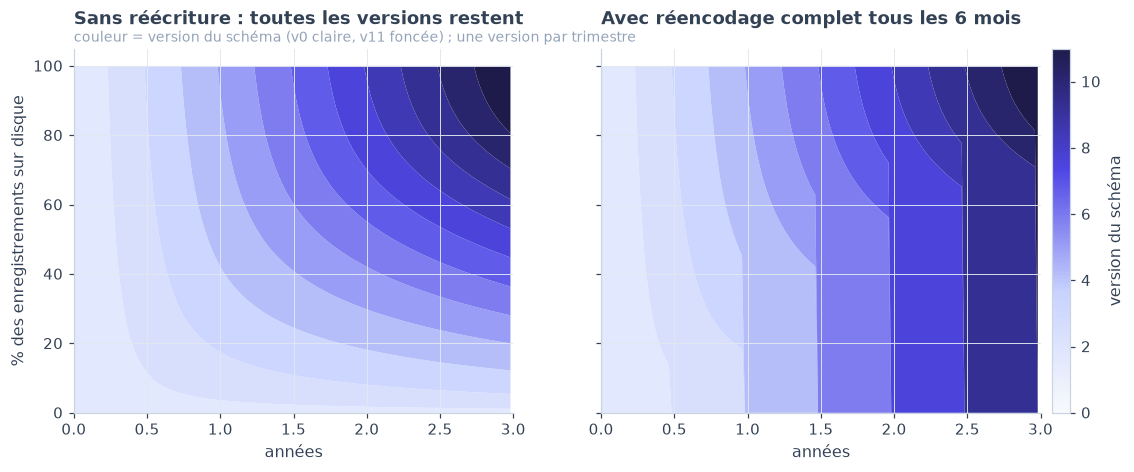

versions présentes en moyenne pendant la 3e année : sans réécriture 10.5 ; avec réencodage 2.4
au bout de 3 ans (sans réécriture) : 1.2% des enregistrements encore en v0, 53% dans une version de plus d'un an


In [5]:
def simuler_versions(semaines=156, nouveaux=2000, trimestre=13, p0=0.30, demi_vie=8.0,
                     compaction_tous=None, seed=0):
    """Version de schéma de chaque enregistrement sur disque, semaine après semaine.

    compaction_tous : si renseigné, tout est réécrit avec la version courante toutes les
    `compaction_tous` semaines (comme une compaction de LSM qui réencode).
    """
    g = np.random.default_rng(seed)
    nais = np.repeat(np.arange(semaines), nouveaux)          # semaine de création
    version = np.full(nais.size, -1)
    hist = []
    for s in range(semaines):
        v = s // trimestre
        vivants = nais <= s
        version[nais == s] = v                               # créations
        age = s - nais[vivants]
        p = p0 * 0.5 ** (age / demi_vie)                     # mises à jour : surtout les jeunes
        maj = g.random(age.size) < p
        idx = np.flatnonzero(vivants)[maj]
        version[idx] = v
        if compaction_tous and s % compaction_tous == compaction_tous - 1:
            version[vivants] = v
        hist.append(np.bincount(version[vivants], minlength=-(-semaines // trimestre)))
    return np.array(hist)

sans = simuler_versions()
avec = simuler_versions(compaction_tous=26)
nv = sans.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), sharey=True)
couleurs = [SEQ(0.15 + 0.85 * k / (nv - 1)) for k in range(nv)]
for ax, h, titre in [(axes[0], sans, "Sans réécriture : toutes les versions restent"),
                     (axes[1], avec, "Avec réencodage complet tous les 6 mois")]:
    frac = h / h.sum(axis=1, keepdims=True) * 100
    ax.stackplot(np.arange(len(h)) / 52, frac.T, colors=couleurs, lw=0)
    ax.set_xlabel("années"); ax.set_title(titre); ax.set_xlim(0, len(h) / 52)
axes[0].set_ylabel("% des enregistrements sur disque")
subtitle(axes[0], "couleur = version du schéma (v0 claire, v11 foncée) ; une version par trimestre")
sm = plt.cm.ScalarMappable(cmap=SEQ, norm=plt.Normalize(0, nv - 1))
fig.colorbar(sm, ax=axes, label="version du schéma", pad=0.01)
plt.show()
an3 = slice(104, 156)
print("versions présentes en moyenne pendant la 3e année : sans réécriture",
      f"{(sans[an3] > 0).sum(axis=1).mean():.1f} ; avec réencodage {(avec[an3] > 0).sum(axis=1).mean():.1f}")
print(f"au bout de 3 ans (sans réécriture) : {sans[-1, 0] / sans[-1].sum():.1%} des enregistrements encore en v0, "
      f"{sans[-1, :8].sum() / sans[-1].sum():.0%} dans une version de plus d'un an")

Sans réécriture, au bout de trois ans, **les douze versions** du schéma cohabitent sur le
disque : plus de la moitié des enregistrements sont encodés avec une version vieille de
plus d'un an, et environ 1 % avec la toute première. Le code actuel doit savoir les lire
tous (compatibilité descendante sur toute l'histoire). Avec un réencodage complet tous
les six mois, il ne reste en moyenne que deux ou trois versions présentes.

Réécrire (migrer) toutes les données coûte cher sur un gros volume, donc la plupart des
bases **diffèrent** ce travail et le font au fil de l'eau : les moteurs de stockage LSM
(chapitre 4) réencodent avec le format le plus récent lors des
**compactions** ; c'est ce que modélise la seconde simulation.

> **À retenir.** Les données survivent au code : une base contient des valeurs encodées
> avec toutes les versions historiques du schéma, sauf réécriture explicite. La
> compatibilité descendante doit couvrir toute cette histoire.

## 4. Migrer sans réécrire, ou réécrire sans interrompre

La plupart des bases relationnelles acceptent des changements de schéma simples **sans
réécrire** les données existantes : ajouter une colonne avec une valeur par défaut nulle
(ou constante) ne touche qu'au catalogue. À la lecture d'une ancienne ligne, la base
complète les colonnes absentes de l'encodage sur disque. Toute la base **paraît** encodée
avec un seul schéma, alors que le stockage mélange des lignes de plusieurs époques.
Mesurons-le avec SQLite : `ALTER TABLE ... ADD COLUMN` contre une reconstruction complète
de la table (ce qu'exigerait une migration qui réécrit chaque ligne).

In [6]:
def mesure(n):
    path = os.path.join(TMP, f"t{n}.db")
    if os.path.exists(path):
        os.remove(path)
    c = sqlite3.connect(path)
    c.execute("CREATE TABLE clients (id INTEGER PRIMARY KEY, nom TEXT, solde REAL)")
    c.executemany("INSERT INTO clients VALUES (?, ?, ?)", ((i, f"client{i}", i * 0.5) for i in range(n)))
    c.commit()
    taille0 = os.path.getsize(path)
    t = time.perf_counter()
    c.execute("ALTER TABLE clients ADD COLUMN pays TEXT DEFAULT 'FR'")
    c.commit()
    t_add = time.perf_counter() - t
    taille1 = os.path.getsize(path)
    t = time.perf_counter()
    c.execute("CREATE TABLE clients2 AS SELECT id, nom, solde, pays, 'EUR' AS devise FROM clients")
    c.commit()
    t_rebuild = time.perf_counter() - t
    defaut = c.execute("SELECT pays FROM clients WHERE id = 0").fetchone()[0]
    c.close()
    return {"lignes": n, "ADD COLUMN (ms)": t_add * 1e3, "reconstruction (ms)": t_rebuild * 1e3,
            "fichier avant (Mo)": taille0 / 1e6, "fichier après ADD (Mo)": taille1 / 1e6, "valeur lue": defaut}

res = pd.DataFrame([mesure(n) for n in [10_000, 50_000, 200_000, 800_000]])
res

,lignes,ADD COLUMN (ms),reconstruction (ms),fichier avant (Mo),fichier après ADD (Mo),valeur lue
0,10000,0.08,0.85,0.25,0.25,FR
1,50000,0.08,4.37,1.29,1.29,FR
2,200000,0.15,18.66,5.39,5.39,FR
3,800000,0.17,75.08,22.04,22.04,FR


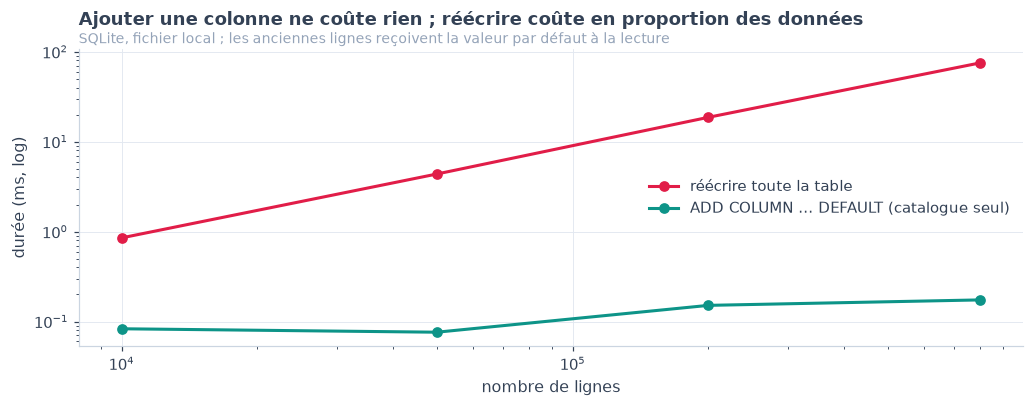

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.loglog(res["lignes"], res["reconstruction (ms)"], "o-", color=ROSE, label="réécrire toute la table")
ax.loglog(res["lignes"], res["ADD COLUMN (ms)"], "o-", color=TEAL, label="ADD COLUMN ... DEFAULT (catalogue seul)")
ax.set_xlabel("nombre de lignes"); ax.set_ylabel("durée (ms, log)")
ax.set_title("Ajouter une colonne ne coûte rien ; réécrire coûte en proportion des données")
subtitle(ax, "SQLite, fichier local ; les anciennes lignes reçoivent la valeur par défaut à la lecture")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

L'ajout de colonne prend une fraction de milliseconde quelle que soit la taille, et le
fichier ne grossit pas : les anciennes lignes ne sont pas réécrites, la valeur `FR` est
fournie à la lecture. La reconstruction, elle, croît linéairement (et sur une vraie base
de production de plusieurs téraoctets, elle se compterait en heures, avec des verrous).

Les changements plus complexes (rendre multivalué un attribut simple, déplacer des données
dans une autre table) exigent en revanche de réécrire les données, souvent au niveau de
l'application. Pour ne pas interrompre le service, on procède alors **par étapes**, en
gardant à chaque instant la compatibilité entre les versions du code en circulation :

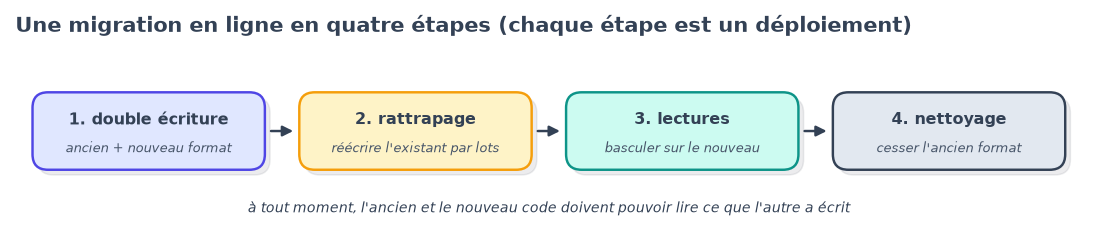

In [8]:
d = Diagram(12.5, 2.0, title="Une migration en ligne en quatre étapes (chaque étape est un déploiement)")
etapes = [("e1", "1. double écriture", "ancien + nouveau format"),
          ("e2", "2. rattrapage", "réécrire l'existant par lots"),
          ("e3", "3. lectures", "basculer sur le nouveau"),
          ("e4", "4. nettoyage", "cesser l'ancien format")]
d.flow(etapes, y=1.15, x0=1.6, dx=3.1, w=2.7, colors=[INDIGO, AMBER, TEAL, SLATE])
d.note(6.25, 0.25, "à tout moment, l'ancien et le nouveau code doivent pouvoir lire ce que l'autre a écrit", color=SLATE)
d.show()

Maintenir la compatibilité dans les deux sens à travers de telles migrations reste un
problème de recherche (le livre cite des travaux sur des « lentilles » qui traduisent
automatiquement entre versions d'un schéma).

> **À retenir.** Les changements simples (ajout d'une colonne avec défaut) se font sans
> réécrire : la base complète les anciennes lignes à la lecture. Les changements
> complexes exigent une réécriture, menée par étapes compatibles pour ne pas
> interrompre le service.

## 5. L'archivage (section *Archival storage*)

On prend régulièrement un instantané de la base, pour la sauvegarde ou pour alimenter un
entrepôt de données. L'instantané est alors généralement encodé avec **le dernier
schéma**, même si la base mélangeait des versions : puisqu'on copie tout, autant encoder
la copie de façon homogène. Écrit d'un coup puis immuable, il convient parfaitement à un
fichier conteneur Avro, ou à un format **orienté colonnes** comme Parquet (chapitre
4), adapté à l'analyse.

Reprenons notre base aux douze versions : simulons des enregistrements dont les champs
dépendent de la version d'écriture (un champ ajouté en v4, un autre en v8), lisons-les
chacun avec son schéma d'écrivain, et produisons un instantané avec le dernier schéma.

In [9]:
def schema_version(v):
    f = [{"name": "id", "type": "long"}, {"name": "nom", "type": "string"}]
    if v >= 4:
        f.append({"name": "pays", "type": ["null", "string"], "default": None})
    if v >= 8:
        f.append({"name": "score", "type": ["null", "double"], "default": None})
    return {"type": "record", "name": "Client", "fields": f}

derniere = schema_version(11)
versions = rng.choice(nv, size=20_000, p=sans[-1] / sans[-1].sum())
stock = []                                        # (version, octets) : la base mélange les encodages
for i, v in enumerate(versions):
    rec = {"id": i, "nom": f"client{i}"}
    if v >= 4:
        rec["pays"] = ["FR", "BE", "CH"][i % 3]
    if v >= 8:
        rec["score"] = round(float(rng.random()), 3)
    stock.append((int(v), E.avro_encode(rec, schema_version(v))))
homogene = [E.avro_decode(b, schema_version(v), derniere) for v, b in stock]
fichier = E.avro_container_write(homogene, derniere)
_, relus = E.avro_container_read(fichier)
print(f"{len(stock)} enregistrements de {len(set(v for v, _ in stock))} versions -> un fichier conteneur de "
      f"{len(fichier) / 1e3:.0f} ko avec un seul schéma")
pd.DataFrame(relus[:4])

20000 enregistrements de 12 versions -> un fichier conteneur de 445 ko avec un seul schéma


,id,nom,pays,score
0,0,client0,FR,0.95
1,1,client1,BE,NaN
2,2,client2,NaN,NaN
3,3,client3,NaN,NaN


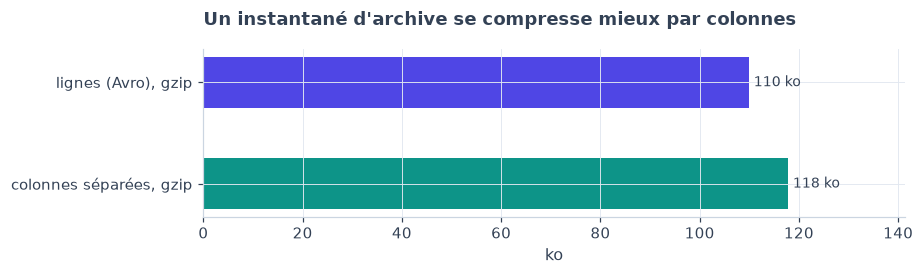

In [10]:
# même instantané, en lignes ou en colonnes, compressé
import gzip
lignes = b"".join(E.avro_encode(r, derniere) for r in homogene)
colonnes = {k: "\n".join(str(r[k]) for r in homogene).encode() for k in ["id", "nom", "pays", "score"]}
tailles = pd.Series({"lignes (Avro), gzip": len(gzip.compress(lignes)),
                     "colonnes séparées, gzip": sum(len(gzip.compress(v)) for v in colonnes.values())}) / 1e3
fig, ax = plt.subplots(figsize=(8.5, 2.6))
ax.barh(tailles.index, tailles.values, color=[INDIGO, TEAL], height=0.5)
for i, v in enumerate(tailles.values):
    ax.text(v + 1, i, f"{v:.0f} ko", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("ko"); ax.set_xlim(0, tailles.max() * 1.2)
ax.set_title("Un instantané d'archive se compresse mieux par colonnes")
plt.tight_layout(); plt.show()

Ranger chaque colonne à part regroupe des valeurs semblables (les pays, les identifiants
croissants), que le compresseur exploite mieux : c'est l'idée des formats en colonnes
vus au chapitre 4, et la raison pour laquelle l'archivage analytique se fait
volontiers en Parquet. Nous reviendrons sur les données d'archive au chapitre
11.

> **À retenir.** Un instantané d'archive est écrit d'un coup, avec le dernier schéma, puis
> reste immuable : fichiers conteneurs Avro ou formats en colonnes s'y prêtent bien.

## Synthèse

- La compatibilité relie un encodeur et un décodeur : il faut identifier qui écrit et qui
  lit, avec quelles versions.
- Une base est un message à son futur soi (compatibilité descendante) et, partagée entre
  instances pendant un déploiement, un canal entre versions (ascendante). Le code
  applicatif doit préserver ce qu'il ne comprend pas.
- Les **données survivent au code** : sans réécriture, toutes les versions historiques
  cohabitent sur le disque ; les compactions et migrations réduisent ce mélange.
- Les changements simples se font sans réécrire (la base complète à la lecture) ; les
  changements complexes se font par étapes compatibles.
- L'archive est encodée d'un coup avec le dernier schéma (Avro, Parquet).

**Pour la suite.** Le cours 5 traite les services (REST et RPC), où l'on peut supposer
que les serveurs sont mis à jour avant les clients, puis le cours 6 les messages.
La réplication (chapitre 6) pose le même problème de versions entre
nœuds qui s'échangent des journaux.